## LexisNexis - Detecting Fraudulent Insurance Claims

### Mukundan Thanigaivelan

In this notebook, we create an ensemble of Random Forest and XGBoost models.

### Import libraries and data

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time, math

from xgboost import XGBClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
  accuracy_score,
  precision_score,
  recall_score,
  average_precision_score,
  f1_score,
  confusion_matrix,
  classification_report
)

In [8]:
df = pd.read_csv('Mukundan_filtered_feature_engineered_fraud_oracle.csv')
df.shape

(15420, 16)

### Prepare data

In [9]:
# Split - train on 1994, test on 1995
train = df.loc[df['Year'] == 1994, :]
test = df.loc[df['Year'] == 1995, :]

In [10]:
X_train = train.drop(columns = ['Year', 'FraudFound_P'])
y_train = train['FraudFound_P']
X_test = test.drop(columns = ['Year', 'FraudFound_P'])
y_test = test['FraudFound_P']

### Train XGBoost + Random Forest Ensemble

- Use optimal hyperparameters from tuners

In [19]:
# Identify feature types
numeric_cols = X_train.select_dtypes(
  include=["number"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
  include=["object"]
).columns.tolist()

In [20]:
# Categorical columns: one-hot encode
categorical_pipeline = Pipeline([
  ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [21]:
# Apply the appropriate transformations
preprocessor = ColumnTransformer([
  ("numeric", "passthrough", numeric_cols),
  ("categorical", categorical_pipeline, categorical_cols)
])

In [22]:
# Define RF classifier
rf = RandomForestClassifier(
  n_estimators=300,
  min_samples_split=10,
  min_samples_leaf=2,
  max_features="log2",
  max_depth=10,
  bootstrap=False,
  class_weight="balanced",
  random_state=42,
  n_jobs=-1
)

In [23]:
# Define XGBoost classifier
xgb = XGBClassifier(
  n_estimators=100,
  subsample=1,
  reg_lambda=5,
  reg_alpha=0.1,
  min_child_weight=1,
  max_depth=4,
  learning_rate=0.1,
  gamma=0,
  colsample_bytree=0.9,
  random_state=42,
  n_jobs=-1
)

In [29]:
# Define ensemble
ensemble = VotingClassifier(
    estimators=[('rf', rf), ('xgb', xgb)], voting='soft', weights=[1,1]
)

# Combine preprocessor and ensemble into one master Pipeline
full_pipeline = Pipeline([('preprocessor', preprocessor), ('model', ensemble)])

# Fit and predict directly on your raw DataFrames
full_pipeline.fit(X_train, y_train)
y_pred = full_pipeline.predict(X_test)
y_prob = full_pipeline.predict_proba(X_test)[:, 1]

In [30]:
# Evaluate
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, y_prob):.4f}")

Accuracy:  0.8964
Precision: 0.1906
Recall:    0.2425
F1-score:  0.2135
PR-AUC:    0.1868


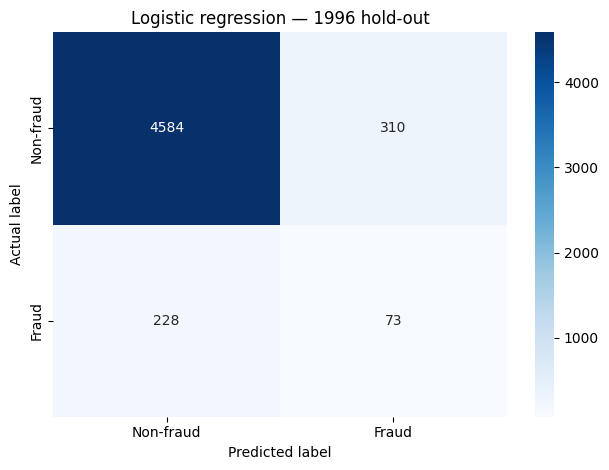

Correctly identified non-fraud: 4584
False alarms: 310
Missed fraud: 228
Fraud cases caught: 73


In [31]:
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-fraud', 'Fraud'], yticklabels=['Non-fraud', 'Fraud'])
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Logistic regression — 1996 hold-out')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = matrix.ravel()
print('Correctly identified non-fraud:', tn)
print('False alarms:', fp)
print('Missed fraud:', fn)
print('Fraud cases caught:', tp)